In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
path = pd.read_csv("Google_Stock_Price_Train.csv")
x = path["Open"].values
Y = path["High"].values
X = np.column_stack((np.ones(len(x)), x))

In [53]:
X_transpose = np.transpose(X)
# LASSO regularization parameter
lambda_value = 0.01
learning_rate = 0.000000001
iterations = 10000
# Initialize theta
theta = np.zeros(X.shape[1])

In [54]:
# LASSO Gradient Descent
for i in range(iterations):
    # Prediction
    Y_pred = X @ theta
    # Error
    error = Y_pred - Y
    # Gradient of MSE
    gradient = (X_transpose @ error) / len(Y)
    # L1 regularization
    # Do not regularize the intercept
    lasso_penalty = lambda_value * np.sign(theta)
    lasso_penalty[0] = 0
    # Update theta
    theta = theta - learning_rate * (gradient + lasso_penalty)


In [55]:
# Final prediction
Y_pred = X @ theta
print("\nTheta after training:")
print(theta)
print("\nPredicted High Price:")
print(Y_pred)
print("\nActual High Price:")
print(Y)


Theta after training:
[0.00166682 0.96140901]

Predicted High Price:
[312.69994802 318.48763028 317.1032013  ... 763.07199977 753.10218832
 752.54457109]

Actual High Price:
[332.83 333.87 330.75 ... 794.23 785.93 782.78]


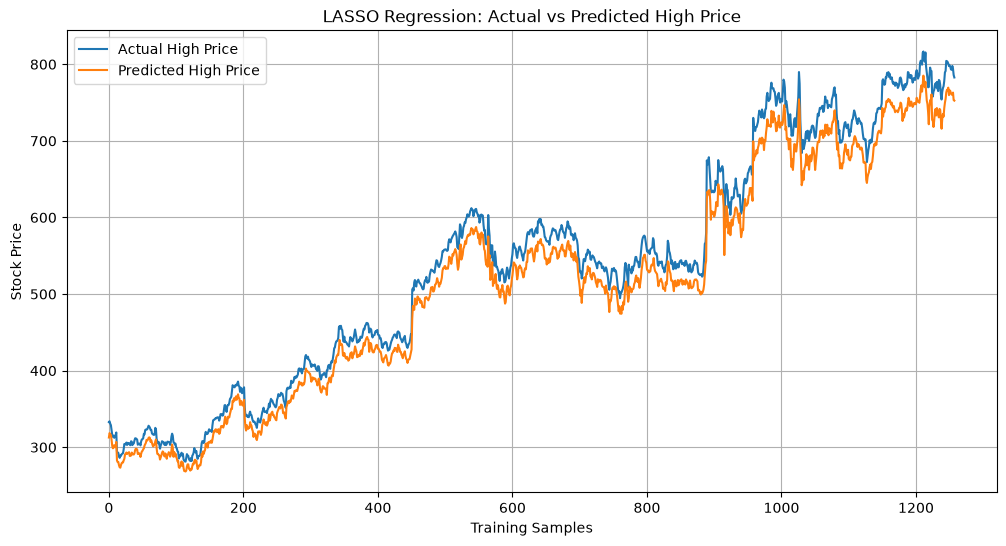

In [56]:
# Plot
plt.figure(figsize=(12, 6))
plt.plot(Y, label="Actual High Price")
plt.plot(Y_pred, label="Predicted High Price")
plt.title("LASSO Regression: Actual vs Predicted High Price")
plt.xlabel("Training Samples")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.show()